# CUB Analyzer: Random Forest model for HEG / LEG prediction

**Machine Learning-Based Analysis of Codon Usage Bias to Distinguish Highly and Lowly Expressed Genes in Prokaryotes**
IBD Project · Group A09

This notebook is the full pipeline behind the CUB Analyzer website:

1. Download all *E. coli* K-12 MG1655 coding sequences from NCBI (Biopython)
2. Label highly expressed (HEG) and lowly expressed (LEG) genes from NCBI annotation
3. Compute codon features: 64 codon frequencies + 59 RSCU values (pandas)
4. Split the genes into a training set and a separate test set, with no gene (or near-identical copy of a gene) in both
5. Train a Random Forest classifier on the training set only (scikit-learn)
6. Evaluate it on the unseen test set: accuracy, F1-score, confusion matrix, plus grouped cross-validation
7. Rank the most important codons
8. Export the trained model so the website can use it

Runs locally or in Google Colab (`pip install biopython` first in Colab).

In [1]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import Entrez, SeqIO
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

SEED = 42
sns.set_theme(style="whitegrid", palette=["#0b6e5f", "#d9822b"])

# Outputs go to the repository root when run from notebook/, otherwise next to the notebook
ROOT = Path("..") if Path("../index.html").exists() else Path(".")
DATA_DIR = ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Download E. coli K-12 coding sequences from NCBI

In [2]:
# NCBI asks for a contact email with Entrez requests: put your own here
Entrez.email = "your.email@example.com"

GENOME = "NC_000913.3"   # Escherichia coli K-12 MG1655, RefSeq
fasta_path = DATA_DIR / "ecoli_k12_cds.fna"
if not fasta_path.exists():
    with Entrez.efetch(db="nuccore", id=GENOME, rettype="fasta_cds_na", retmode="text") as handle:
        fasta_path.write_text(handle.read())

def tag(description, key):
    marker = f"[{key}="
    if marker not in description:
        return ""
    return description.split(marker, 1)[1].split("]", 1)[0]

genes = pd.DataFrame([
    {
        "gene": tag(r.description, "gene"),
        "locus": tag(r.description, "locus_tag"),
        "product": tag(r.description, "protein"),
        "pseudo": "[pseudo=true]" in r.description,
        "seq": str(r.seq).upper(),
    }
    for r in SeqIO.parse(fasta_path, "fasta")
])
print(f"{len(genes)} coding sequences downloaded from {GENOME}")
genes.head()

4318 coding sequences downloaded from NC_000913.3


,gene,locus,product,pseudo,seq
0,thrL,b0001,thr operon leader peptide,False,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...
1,thrA,b0002,fused aspartate kinase/homoserine dehydrogenase 1,False,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...
2,thrB,b0003,homoserine kinase,False,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...
3,thrC,b0004,threonine synthase,False,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...
4,yaaX,b0005,DUF2502 domain-containing protein YaaX,False,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...


## 2. Label HEG and LEG genes

NCBI does not label expression level, so genes are labelled by function, following the classic codon-bias reference sets:

* **HEG**: ribosomal proteins (except the rarely made paralogs *ykgM*, *ykgO*), translation factors, chaperones, major outer-membrane proteins, glycolysis, TCA cycle and ATP-synthase genes
* **LEG**: DNA-binding transcriptional regulators, kept at low levels in the cell; highly expressed global regulators are excluded

LEG candidates are evenly sampled down to the same number as HEG, so the classes are balanced.

In [3]:
EXTRA_HEG = set("""tufA tufB tsf fusA tig infB infC frr efp ompA ompC ompF lpp groL groS dnaK htpG clpB
gapA eno pgk fbaA tpiA pykF pgi aceE aceF lpd sucC sucD gltA atpA atpB atpC atpD atpE atpF atpG atpH
ahpC sodA rpoA rpoB rpoC hupA hupB ihfA ihfB fis hns cspA dps""".split())
GLOBAL_REGULATORS = set("crp fis hns lrp fnr arcA ompR cra stpA nac fur ihfA ihfB".split())

valid = genes[
    ~genes.pseudo
    & (genes.seq.str.len() % 3 == 0)
    & (genes.seq.str.len() >= 150)
    & genes.seq.str.fullmatch("[ACGT]+")
]

# NCBI lists a few genes more than once (alternative start sites, e.g. clpB / ClpB80, infB isoforms).
# Their sequences overlap almost completely, so keep only the longest record per gene.
n_before = len(valid)
valid = (valid.assign(length=valid.seq.str.len())
              .sort_values("length", ascending=False)
              .drop_duplicates("locus")
              .drop(columns="length"))
print(f"Removed {n_before - len(valid)} duplicate records of the same gene")

is_ribosomal = valid["product"].str.contains("ribosomal subunit protein") & ~valid.gene.isin(["ykgO", "ykgM"])
heg = valid[is_ribosomal | valid.gene.isin(EXTRA_HEG)].sort_values("locus")

leg_all = valid[
    valid["product"].str.contains("DNA-binding transcriptional")
    & ~valid.gene.isin(GLOBAL_REGULATORS) & ~valid.gene.isin(EXTRA_HEG)
].sort_values("locus")
step = len(leg_all) / len(heg)
leg = leg_all.iloc[[math.floor(i * step) for i in range(len(heg))]]

dataset = pd.concat([heg.assign(label="HEG"), leg.assign(label="LEG")], ignore_index=True)
print(f"HEG: {len(heg)}   LEG: {len(leg)} (sampled from {len(leg_all)} regulators)")
dataset[["gene", "locus", "label", "product"]].sample(8, random_state=SEED)

Removed 9 duplicate records of the same gene


HEG: 104   LEG: 104 (sampled from 252 regulators)


,gene,locus,label,product
161,yfhH,b2561,LEG,putative DNA-binding transcriptional regulator...
15,dps,b0812,HEG,DNA protection during starvation protein
73,rpsG,b3341,HEG,30S ribosomal subunit protein S7
96,hupA,b4000,HEG,DNA-binding protein HU-alpha
166,fhlA,b2731,LEG,DNA-binding transcriptional activator FhlA
9,hupB,b0440,HEG,DNA-binding protein HU-beta
100,efp,b4147,HEG,protein chain elongation factor EF-P
135,yddM,b1477,LEG,DNA-binding transcriptional regulator YddM


## 3. Codon features: frequency + RSCU

* **Codon frequency**: count of each of the 64 codons ÷ total codons
* **RSCU** (relative synonymous codon usage): observed count ÷ count expected if all synonymous codons were used equally; computed for the 59 codons of amino acids with more than one codon (no Met, Trp or stops)

In [4]:
BASES = "TCAG"
AA = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODONS = [a + b + c for a in BASES for b in BASES for c in BASES]
CODON_TO_AA = dict(zip(CODONS, AA))
FAMILIES = {}
for c in CODONS:
    FAMILIES.setdefault(CODON_TO_AA[c], []).append(c)
RSCU_CODONS = [c for c in CODONS if CODON_TO_AA[c] != "*" and len(FAMILIES[CODON_TO_AA[c]]) > 1]
FEATURES = [f"freq_{c}" for c in CODONS] + [f"rscu_{c}" for c in RSCU_CODONS]

def codon_features(seq):
    counts = dict.fromkeys(CODONS, 0)
    usable = len(seq) - len(seq) % 3
    for i in range(0, usable, 3):
        counts[seq[i:i + 3]] += 1
    total = usable // 3
    freq = [counts[c] / total if total else 0.0 for c in CODONS]
    rscu = {}
    for fam in FAMILIES.values():
        s = sum(counts[c] for c in fam)
        for c in fam:
            rscu[c] = counts[c] * len(fam) / s if s else 0.0
    return freq + [rscu[c] for c in RSCU_CODONS]

X = pd.DataFrame([codon_features(s) for s in dataset.seq], columns=FEATURES)
y = (dataset.label == "HEG").astype(int)
print(f"Feature matrix: {X.shape[0]} genes × {X.shape[1]} features ({len(CODONS)} frequencies + {len(RSCU_CODONS)} RSCU)")
X.iloc[:5, 64:72]

Feature matrix: 208 genes × 123 features (64 frequencies + 59 RSCU)


,rscu_TTT,rscu_TTC,rscu_TTA,rscu_TTG,rscu_TCT,rscu_TCC,rscu_TCA,rscu_TCG
0,0.666667,1.333333,0.000000,0.000000,3.360000,1.440000,0.000000,0.000000
1,1.000000,1.000000,0.000000,1.500000,3.000000,0.000000,1.500000,0.000000
2,0.058824,1.941176,0.000000,0.085714,1.813953,1.395349,0.279070,0.837209
3,0.526316,1.473684,0.000000,0.181818,2.482759,1.034483,0.206897,1.241379
4,0.285714,1.714286,0.176471,0.000000,2.142857,1.714286,0.428571,0.000000


Quick look: average RSCU of a few well-known codon pairs in HEG vs LEG.

In [5]:
pairs = ["rscu_CTG", "rscu_CTT", "rscu_CGT", "rscu_AGA", "rscu_AAC", "rscu_AAT", "rscu_GGT", "rscu_GGA"]
X[pairs].groupby(dataset.label).mean().T.round(2)

label,HEG,LEG
rscu_CTG,4.93,2.45
rscu_CTT,0.34,0.74
rscu_CGT,3.92,1.87
rscu_AGA,0.05,0.36
rscu_AAC,1.70,0.85
rscu_AAT,0.30,1.15
rscu_GGT,2.24,1.10
rscu_GGA,0.06,0.60


## 4. Train / test split

The model must be tested on genes it has never seen. Two things could leak training genes into the test set:

* **The same gene twice**: already removed in step 2.
* **Near-identical copies of a gene**: *E. coli* has duplicated genes such as *tufA* / *tufB* (EF-Tu), whose DNA is almost the same. If one copy were in training and the other in testing, the test would be too easy.

So genes with the same length and at least 90% identical sequence are put in the same **group**, and a whole group always goes to the same side. `StratifiedGroupKFold` then holds out 25% of the genes as the test set, keeping HEG and LEG balanced.

In [6]:
seqs = dataset.seq.tolist()
parent = list(range(len(seqs)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for i in range(len(seqs)):
    for j in range(i + 1, len(seqs)):
        a, b = seqs[i], seqs[j]
        if len(a) == len(b) and sum(x == y for x, y in zip(a, b)) / len(a) >= 0.90:
            parent[find(j)] = find(i)
groups = pd.Series([find(i) for i in range(len(seqs))], index=dataset.index)
merged = groups[groups.duplicated(keep=False)]
for g, members in dataset.loc[merged.index].groupby(merged)["gene"]:
    print("Kept together:", ", ".join(members))

splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_pos, test_pos = next(splitter.split(X, y, groups))
idx_train, idx_test = dataset.index[train_pos], dataset.index[test_pos]

# Checks: nothing is shared between the two sets
train_genes, test_genes = dataset.loc[idx_train], dataset.loc[idx_test]
assert set(train_genes.locus).isdisjoint(test_genes.locus), "a gene is in both sets"
assert set(groups[idx_train]).isdisjoint(groups[idx_test]), "near-identical genes are split"
assert not any(t in s or s in t for t in test_genes.seq for s in train_genes.seq), "overlapping sequences"
print("No gene, duplicate or near-identical copy appears in both sets.")

split_table = pd.crosstab(np.where(dataset.index.isin(idx_test), "test", "train"), dataset.label, margins=True)
split_table

Kept together: tufA, tufB


No gene, duplicate or near-identical copy appears in both sets.

label,HEG,LEG,All
row_0,,,
test,26,26,52
train,78,78,156
All,104,104,208


## 5. Train the Random Forest (training set only)

In [7]:
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

model = RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=SEED, n_jobs=-1)
model.fit(X_train, y_train)
print(f"Trained on {len(X_train)} genes, testing on {len(X_test)} unseen genes")

Trained on 156 genes, testing on 52 unseen genes


## 6. Evaluate on the held-out test genes

In [8]:
heg_col = list(model.classes_).index(1)
proba_test = model.predict_proba(X_test)[:, heg_col]
pred_test = (proba_test >= 0.5).astype(int)

metrics = {
    "accuracy": accuracy_score(y_test, pred_test),
    "precision": precision_score(y_test, pred_test),
    "recall": recall_score(y_test, pred_test),
    "f1": f1_score(y_test, pred_test),
}
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
metrics.update(tp=int(tp), fn=int(fn), fp=int(fp), tn=int(tn))

# Cross-validation repeats the split 5 times (same grouping rule) to check the score is stable
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=SEED, n_jobs=-1), X, y, groups=groups, cv=cv)

for k in ["accuracy", "precision", "recall", "f1"]:
    print(f"{k:>10}: {metrics[k]:.3f}")
print(f"5-fold CV accuracy: {cv_scores.mean():.1%} ± {cv_scores.std():.1%}")
print()
print(classification_report(y_test, pred_test, target_names=["LEG", "HEG"]))

  accuracy: 0.981
 precision: 1.000
    recall: 0.962
        f1: 0.980
5-fold CV accuracy: 95.7% ± 2.8%

              precision    recall  f1-score   support

         LEG       0.96      1.00      0.98        26
         HEG       1.00      0.96      0.98        26

    accuracy                           0.98        52
   macro avg       0.98      0.98      0.98        52
weighted avg       0.98      0.98      0.98        52



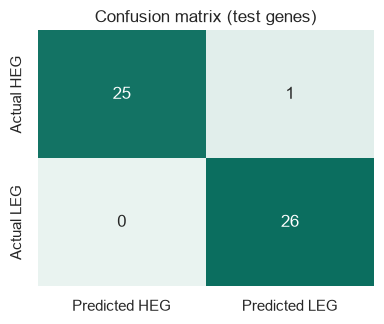

In [9]:
fig, ax = plt.subplots(figsize=(4, 3.4))
sns.heatmap([[tp, fn], [fp, tn]], annot=True, fmt="d", cmap=sns.light_palette("#0b6e5f", as_cmap=True), cbar=False,
            xticklabels=["Predicted HEG", "Predicted LEG"], yticklabels=["Actual HEG", "Actual LEG"], ax=ax)
ax.set_title("Confusion matrix (test genes)")
plt.tight_layout()
plt.show()

### Comparison: Codon Adaptation Index (CAI)

CAI scores a gene by how close its codons are to the codons used in highly expressed E. coli genes (Sharp & Li 1987 weights). A simple rule, CAI ≥ 0.50 → HEG, gives a non-ML baseline on the same test genes.

In [10]:
W_ECOLI = {
    "TTT": 0.296, "TTC": 1.000, "TTA": 0.020, "TTG": 0.020, "CTT": 0.042, "CTC": 0.037, "CTA": 0.007, "CTG": 1.000,
    "ATT": 0.185, "ATC": 1.000, "ATA": 0.003, "GTT": 1.000, "GTC": 0.066, "GTA": 0.495, "GTG": 0.221,
    "TCT": 1.000, "TCC": 0.744, "TCA": 0.077, "TCG": 0.017, "AGT": 0.085, "AGC": 0.410,
    "CCT": 0.070, "CCC": 0.012, "CCA": 0.135, "CCG": 1.000, "ACT": 0.965, "ACC": 1.000, "ACA": 0.076, "ACG": 0.099,
    "GCT": 1.000, "GCC": 0.122, "GCA": 0.586, "GCG": 0.424, "TAT": 0.239, "TAC": 1.000, "CAT": 0.291, "CAC": 1.000,
    "CAA": 0.124, "CAG": 1.000, "AAT": 0.051, "AAC": 1.000, "AAA": 1.000, "AAG": 0.253, "GAT": 0.434, "GAC": 1.000,
    "GAA": 1.000, "GAG": 0.259, "TGT": 0.500, "TGC": 1.000,
    "CGT": 1.000, "CGC": 0.356, "CGA": 0.004, "CGG": 0.004, "AGA": 0.004, "AGG": 0.002,
    "GGT": 1.000, "GGC": 0.724, "GGA": 0.010, "GGG": 0.019,
}

def cai(seq):
    logs = [math.log(W_ECOLI[seq[i:i + 3]]) for i in range(0, len(seq) - 2, 3) if seq[i:i + 3] in W_ECOLI]
    return math.exp(sum(logs) / len(logs)) if logs else float("nan")

cai_test = dataset.loc[idx_test, "seq"].map(cai)
cai_accuracy = accuracy_score(y_test, (cai_test >= 0.5).astype(int))
print(f"Random Forest accuracy: {metrics['accuracy']:.3f}")
print(f"CAI rule accuracy:      {cai_accuracy:.3f}")

Random Forest accuracy: 0.981
CAI rule accuracy:      0.981


## 7. Most important codons (learned from the training set)

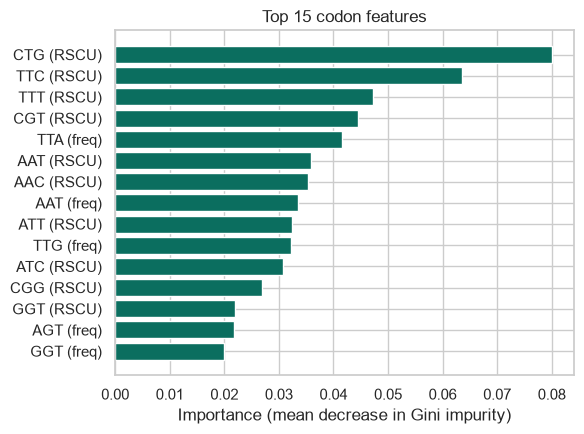

rscu_CTG    0.0801
rscu_TTC    0.0635
rscu_TTT    0.0473
rscu_CGT    0.0445
freq_TTA    0.0416
rscu_AAT    0.0358
rscu_AAC    0.0353
freq_AAT    0.0335
rscu_ATT    0.0323
freq_TTG    0.0322
rscu_ATC    0.0307
rscu_CGG    0.0268
rscu_GGT    0.0219
freq_AGT    0.0217
freq_GGT    0.0199
dtype: float64

In [11]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
top = importance.head(15)

fig, ax = plt.subplots(figsize=(6, 4.5))
labels = [f"{n.split('_')[1]} ({'RSCU' if n.startswith('rscu') else 'freq'})" for n in top.index]
ax.barh(labels[::-1], top.values[::-1], color="#0b6e5f")
ax.set_xlabel("Importance (mean decrease in Gini impurity)")
ax.set_title("Top 15 codon features")
plt.tight_layout()
plt.show()
top.round(4)

## 8. Export for the website

The trained scikit-learn forest is written to `model/model-data.js`: every tree's split features, thresholds and leaf probabilities, plus the test metrics, the codon importances and the held-out test genes. The website runs these exact trees in the browser, so its predictions are the scikit-learn model's predictions.

The feature table is also saved to `data/cub_dataset.csv`.

In [12]:
def export_tree(estimator):
    t = estimator.tree_
    values = t.value[:, 0, :]
    p_heg = values[:, heg_col] / values.sum(axis=1)
    leaf = t.children_left == -1
    return {
        "f": np.where(leaf, -1, t.feature).tolist(),
        "t": [0 if l else float(th) for l, th in zip(leaf, t.threshold)],
        "l": t.children_left.tolist(),
        "r": t.children_right.tolist(),
        "p": [round(float(v), 6) for v in p_heg],
    }

test_rows = dataset.loc[idx_test]
export = {
    "trainedWith": f"scikit-learn {sklearn.__version__}",
    "features": FEATURES,
    "nGenes": int(len(dataset)),
    "nHeg": int((dataset.label == "HEG").sum()),
    "nLeg": int((dataset.label == "LEG").sum()),
    "nLegCandidates": int(len(leg_all)),
    "nTrain": int(len(idx_train)),
    "nTest": int(len(idx_test)),
    "metrics": {k: (round(float(v), 6) if isinstance(v, float) else v) for k, v in metrics.items()},
    "cvAccuracy": [round(float(cv_scores.mean()), 6), round(float(cv_scores.std()), 6)],
    "caiAccuracy": round(float(cai_accuracy), 6),
    "importance": [round(float(v), 6) for v in model.feature_importances_],
    "testGenes": test_rows[["gene", "locus", "label", "product", "seq"]].values.tolist(),
    "testProba": [round(float(p), 6) for p in proba_test],
    "trees": [export_tree(e) for e in model.estimators_],
}

js = ("// Generated by notebook/cub_model.ipynb: Random Forest trained with "
      f"scikit-learn {sklearn.__version__} on NCBI E. coli K-12 genes. Do not edit by hand.\n"
      "const CUB_MODEL = " + json.dumps(export, separators=(",", ":")) + ";\n")
(ROOT / "model").mkdir(exist_ok=True)
(ROOT / "model" / "model-data.js").write_text(js, encoding="utf-8")

table = dataset[["gene", "locus", "product", "label"]].assign(
    split=np.where(dataset.index.isin(idx_test), "test", "train")).join(X)
table.to_csv(DATA_DIR / "cub_dataset.csv", index=False)

print(f"model/model-data.js: {len(js) / 1024:.0f} KB, {len(model.estimators_)} trees, "
      f"{sum(e.tree_.node_count for e in model.estimators_)} nodes")
print(f"data/cub_dataset.csv: {table.shape[0]} rows × {table.shape[1]} columns")

model/model-data.js: 138 KB, 200 trees, 3470 nodes
data/cub_dataset.csv: 208 rows × 128 columns
